<a href="https://colab.research.google.com/github/Puerinn/TUGAS-UTS-ML-B13/blob/main/notebook_uts_gempa_B13.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Karakteristik Kejadian Gempa Indonesia Berdasarkan Waktu, Lokasi, dan Magnitudo

**Project ID:** B13   
**Kelompok:** 9  
**Metode:** Reduksi Dimensi & Pencarian Pola (unsupervised learning, classical machine learning)  
**Anggota:**<br>  Dedi Sanjaya Nainggolan (231111885)<br>Erico Adelorenzo Samosir (231112600)<br>Andi Aziz Prasetyo (231112637)

**Dataset:** USGS Earthquake Catalog (ComCat), wilayah Indonesia, 2010–2025, M ≥ 4,0 — https://earthquake.usgs.gov/earthquakes/search/

**Isi notebook dan padanannya dengan komponen laporan Milestone 1:**

| Bagian | Isi | Komponen laporan |
|---|---|---|
| 1 | Perumusan masalah | A |
| 2 | Dataset dan pemahaman data | B |
| 3 | EDA dan temuan awal | C |
| 4 | Preprocessing, pembagian data, dan rekayasa fitur awal | D, E |
| 5 | Rancangan evaluasi | G |
| 6 | Baseline dan model kandidat | F |
| 7 | Hasil eksperimen awal dan analisis | H |
| 8 | Dokumentasi dan rencana lanjutan | I |



---
# 1. Perumusan Masalah *(Komponen A)*

## 1.1 Identifikasi Proyek

| Informasi | Keterangan |
|---|---|
| Project ID | B13 |
| Topik proyek | Karakteristik kejadian gempa berdasarkan waktu, lokasi, dan magnitudo |
| Masalah yang dikaji | Gempa di Indonesia terjadi di banyak zona tektonik dengan karakter berbeda (lokasi, kedalaman, magnitudo). Dengan puluhan ribu kejadian dan banyak fitur sekaligus, pola umum sulit dilihat secara manual. Belum diketahui apakah kejadian gempa memiliki struktur atau kelompok yang dapat ditemukan otomatis, dan fitur mana yang membawa struktur itu. |
| Tujuan proyek | Meringkas fitur kejadian gempa dengan reduksi dimensi, menemukan pola atau kelompok gempa dengan clustering, serta menguji apakah fitur waktu menambah struktur dan apakah struktur bertahan antar periode. |
| Unit observasi | **Satu kejadian gempa** (25.057 kejadian setelah pembersihan) |
| Target/label | **Tidak ada** (unsupervised) |
| Pendekatan ML | Reduksi dimensi (PCA, t-SNE, UMAP) dan clustering (K-Means, GMM, DBSCAN) |
| Target keluaran | Tabel perbandingan baseline vs kandidat, peta cluster zona seismik, serta temuan tentang fitur yang membawa struktur |

## 1.2 Latar Belakang
Indonesia berada di pertemuan beberapa lempeng tektonik sehingga sangat sering mengalami gempa. Mengelompokkan gempa menurut karakternya (lokasi, kedalaman, magnitudo, waktu) membantu memahami zona seismik, memisahkan gempa dangkal dari gempa dalam, dan menjadi dasar analisis lanjutan seperti kajian risiko wilayah.

## 1.3 Pertanyaan Analisis
1. Berapa dimensi efektif data gempa, dan fitur mana yang paling banyak menjelaskan variasinya (PCA)?
2. Apakah ada kelompok gempa yang dapat ditemukan, dan apakah reduksi dimensi memperbaikinya dibanding tanpa reduksi?
3. Apakah fitur waktu (bulan, jam) membentuk struktur, atau hanya menambah derau?
4. Apakah struktur yang ditemukan pada 2010–2017 bertahan pada 2018–2025?
5. Apakah cluster berdasarkan lokasi mengikuti zona seismik dan berkaitan dengan kedalaman?

## 1.4 Kriteria Keberhasilan
Karena tidak ada label, keberhasilan tidak diukur dengan akurasi, tetapi dengan tiga hal: (1) baseline dan kandidat dibandingkan secara konsisten dengan metrik internal pada data latih dan data uji; (2) struktur dianggap bermakna jika kualitas cluster pada periode uji mendekati periode latih dan hasilnya stabil pada bootstrap; (3) cluster dapat ditafsirkan secara geografis (zona, kedalaman). Hasil yang menunjukkan struktur lemah atau tidak ada (misalnya pada fitur waktu) tetap merupakan temuan yang sah selama didukung bukti.

## 1.5 Batasan
- Data USGS dengan M ≥ 4,0 untuk kotak koordinat Indonesia, 2010–2025; kejadian di negara tetangga dikeluarkan.
- Tidak ada prediksi gempa; proyek hanya mendeskripsikan pola pada katalog.
- Tidak ada label kebenaran, sehingga evaluasi memakai metrik internal.
- Tuning menyeluruh dan pemilihan model final merupakan tahap setelah UTS.

---
# 2. Dataset dan Pemahaman Data *(Komponen B)*

## 2.1 Sumber dan Parameter Pengambilan Data

| Informasi | Keterangan |
|---|---|
| Sumber | USGS Earthquake Catalog (Comprehensive Earthquake Catalog, ComCat), U.S. Geological Survey |
| Tautan | https://earthquake.usgs.gov/earthquakes/search/ |
| API yang dipakai | FDSN Event Web Service — https://earthquake.usgs.gov/fdsnws/event/1/ |
| Format | CSV |
| Wilayah | Lintang −11° s.d. 6°, bujur 95° s.d. 141° (kotak persegi) |
| Periode | 1 Januari 2010 s.d. 31 Desember 2025 |
| Magnitudo minimum | 4,0 |
| Tanggal akses | 6 Oktober 2026 |
| Cara memperoleh ulang | Jalankan sel di bawah; unduhan dipecah per tahun karena batas 20.000 kejadian per permintaan |

### Import library

In [4]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import (silhouette_score, davies_bouldin_score, calinski_harabasz_score,
                             adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
SIL_SAMPLE = 5000
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
PAKAI_CSV_BERSIH = True
CSV_BERSIH = "gempa_indonesia_bersih.csv"


### Pengambilan data dari USGS

In [5]:
if PAKAI_CSV_BERSIH:
    print("Mode CSV bersih: unduhan USGS dilewati (lihat bagian 2.2)")
else:
    RAW = "usgs_raw.csv"
    BASE = ("https://earthquake.usgs.gov/fdsnws/event/1/query?format=csv"
            "&minmagnitude=4&minlatitude=-11&maxlatitude=6&minlongitude=95&maxlongitude=141")

    if os.path.exists(RAW):
        raw = pd.read_csv(RAW)
        print("Dimuat dari", RAW)
    else:
        parts = []
        for y in range(2010, 2026):
            url = f"{BASE}&starttime={y}-01-01&endtime={y+1}-01-01"
            p = pd.read_csv(url)
            print(y, len(p), "kejadian")
            parts.append(p)
        raw = pd.concat(parts, ignore_index=True)
        raw.to_csv(RAW, index=False)

    n_dup = raw.duplicated("id").sum()
    raw = raw.drop_duplicates("id").reset_index(drop=True)
    print("Data mentah:", raw.shape, "| duplikat id dibuang:", n_dup)
    print(raw["type"].value_counts())

Mode CSV bersih: unduhan USGS dilewati (lihat bagian 2.2)


**Hasil:** data mentah berisi 30.435 kejadian dengan 22 kolom; tidak ada duplikat `id`, dan seluruh baris bertipe `earthquake`.

**Implikasi:** tidak perlu menyaring jenis kejadian, tetapi wilayah kotak persegi memuat negara tetangga sehingga perlu dibersihkan (bagian 2.2).

## 2.2 Pembersihan Awal: Penyaringan Wilayah

Kotak koordinat memuat sebagian Filipina, Timor Leste, Papua Nugini, Palau, Malaysia, dan Australia. Kejadian di negara tetangga dibuang berdasarkan akhiran kolom `place`; perairan Indonesia (Banda Sea, Molucca Sea, dst.) **dipertahankan**. Hanya tujuh kolom yang dipertahankan, karena kolom kualitas bawaan USGS banyak yang kosong dan tidak dipakai.

In [6]:
KEEP = ["time", "latitude", "longitude", "depth", "mag", "magType", "place"]
if PAKAI_CSV_BERSIH:
    df = pd.read_csv(CSV_BERSIH)[KEEP].copy()
    df["time"] = pd.to_datetime(df["time"], utc=True, format="ISO8601")
    df = df.sort_values("time").reset_index(drop=True)
    print("Data bersih dimuat dari", CSV_BERSIH, "->", df.shape)
else:
    BUANG = ["Philippines", "Timor Leste", "Papua New Guinea", "Palau", "Malaysia",
             "Australia", "Singapore", "Thailand", "India", "Myanmar", "Brunei",
             "Philippine Islands region", "East Timor region", "Timor region", "Palau region"]
    KEEP = ["time", "latitude", "longitude", "depth", "mag", "magType", "place"]

    n0 = len(raw)
    df = raw[raw["type"] == "earthquake"]
    n_bukan_gempa = n0 - len(df)

    suffix = df["place"].fillna("").str.split(",").str[-1].str.strip()
    n_sebelum_negara = len(df)
    df = df[~suffix.isin(BUANG)][KEEP].copy()
    try:
        df["time"] = pd.to_datetime(df["time"], utc=True, format="ISO8601")
    except Exception:
        df["time"] = pd.to_datetime(df["time"], utc=True)
    df = df.sort_values("time").reset_index(drop=True)

    print(f"Mentah                      : {n0}")
    print(f"Dibuang (bukan 'earthquake'): {n_bukan_gempa}")
    print(f"Dibuang (negara tetangga)   : {n_sebelum_negara - len(df)}")
    print(f"Data bersih                 : {len(df)}")
    print(df["place"].str.split(",").str[-1].str.strip().value_counts().head(12))

Data bersih dimuat dari gempa_indonesia_bersih.csv -> (25057, 7)


**Hasil:** 30.435 → **25.057** kejadian (5.378 negara tetangga dibuang, 0 bukan gempa). Wilayah yang tersisa hanya Indonesia dan perairannya.

**Interpretasi:** penyaringan memakai teks `place`, sehingga ketepatannya bergantung pada pelabelan USGS.

**Implikasi:** 25.057 kejadian ini menjadi dataset kerja untuk semua analisis berikutnya.

## 2.3 Kamus Data dan Struktur Data

| Kolom | Arti | Tipe | Satuan / nilai | Catatan |
|---|---|---|---|---|
| `time` | Waktu kejadian | datetime (UTC) | 2010-01-01 s.d. 2025-12-31 | Zona waktu UTC |
| `latitude` | Lintang episenter | numerik | derajat (−11,00 s.d. 5,97) | Negatif = selatan |
| `longitude` | Bujur episenter | numerik | derajat (95,01 s.d. 140,97) | Positif = timur |
| `depth` | Kedalaman hiposenter | numerik | km (0 s.d. 652,53) | Memuat nilai berulang 10 km dan 35 km |
| `mag` | Magnitudo | numerik | 4,0 s.d. 7,8 | Skala berbeda-beda (lihat `magType`) |
| `magType` | Jenis skala magnitudo | kategorik | mb, mww, mwc, mwb, mwr, m | `mb` 93,7% |
| `place` | Keterangan lokasi | teks | mis. "161 km SSW of Singkil, Indonesia" | Dipakai hanya untuk penyaringan wilayah |

Kolom bawaan USGS lainnya (15 kolom, mis. `nst`, `gap`, `dmin`, `rms`, `net`, `horizontalError`, `depthError`, `magError`, `magNst`) tidak dipakai karena tidak relevan atau banyak yang kosong. **Unit observasi:** satu kejadian gempa. **Target:** tidak ada.

In [7]:
deskripsi = pd.DataFrame({
    "fitur": ["time", "latitude", "longitude", "depth", "mag", "magType", "place"],
    "deskripsi": ["Waktu kejadian (UTC)", "Lintang episenter (derajat)", "Bujur episenter (derajat)",
                  "Kedalaman hiposenter (km)", "Magnitudo", "Jenis skala magnitudo (mb, mww, ...)",
                  "Keterangan lokasi teks (jarak & arah dari kota terdekat)"],
    "tipe": ["datetime", "numerik", "numerik", "numerik", "numerik", "kategorik", "teks"],
})
print(deskripsi.to_string(index=False))
print("\nJumlah observasi:", len(df), "| jumlah fitur asli:", df.shape[1])
print("\nNilai kosong per kolom:\n", df.isna().sum())
print("\nRingkasan statistik:\n", df[["latitude", "longitude", "depth", "mag"]].describe().round(2))
print("\nmagType:\n", df["magType"].value_counts())
print("\nNilai kedalaman yang paling sering (kemungkinan nilai bawaan USGS):")
print(df["depth"].round(1).value_counts().head(8))

    fitur                                                deskripsi      tipe
     time                                     Waktu kejadian (UTC)  datetime
 latitude                              Lintang episenter (derajat)   numerik
longitude                                Bujur episenter (derajat)   numerik
    depth                                Kedalaman hiposenter (km)   numerik
      mag                                                Magnitudo   numerik
  magType                     Jenis skala magnitudo (mb, mww, ...) kategorik
    place Keterangan lokasi teks (jarak & arah dari kota terdekat)      teks

Jumlah observasi: 25057 | jumlah fitur asli: 7

Nilai kosong per kolom:
 time         0
latitude     0
longitude    0
depth        0
mag          0
magType      0
place        0
dtype: int64

Ringkasan statistik:
        latitude  longitude     depth       mag
count  25057.00   25057.00  25057.00  25057.00
mean      -2.78     121.10     77.17      4.50
std        4.17      12.12  

**Hasil:**
- 25.057 observasi dan 7 kolom asli; tidak ada nilai kosong pada ketujuh kolom.
- Magnitudo rata-rata 4,50 (simpangan baku 0,39), maksimum 7,8. Kedalaman median 44,6 km, rata-rata 77,2 km, maksimum 652,5 km.
- `magType`: `mb` 23.483 (93,7%), `mww` 1.208, `mwc` 248, `mwb` 99, `mwr` 18, `m` 1.
- Kedalaman tepat 10,0 km muncul 4.600 kali dan 35,0 km muncul 2.006 kali.

**Implikasi:** tidak diperlukan imputasi; nilai kedalaman berulang dan skala magnitudo bercampur perlu dicatat sebagai keterbatasan.

## 2.4 Temuan Kualitas Data

| No | Temuan | Bukti | Implikasi |
|---|---|---|---|
| 1 | **Kolom inti lengkap, kolom kualitas banyak kosong** | Tujuh kolom inti tanpa nilai kosong; pada data mentah `nst` kosong 18.140 dari 30.435 baris, `horizontalError` 7.262, `magError` 5.266 | Tidak ada imputasi; kolom kualitas tidak dipakai |
| 2 | **Wilayah kotak memuat negara tetangga** | 5.378 baris dibuang (Philippines 2.652, Timor Leste 2.605, Papua Nugini 52, Palau 37, Malaysia 11, dst.) | Disaring lewat `place`; ketepatannya bergantung label USGS (mis. 1 kejadian "South Indian Ocean" dipertahankan) |
| 3 | **Kedalaman bernilai berulang** | 10,0 km: 4.600 kejadian (18,4%); 35,0 km: 2.006 (8,0%); total ≈ 26,4% | Kemungkinan nilai bawaan saat kedalaman tak dapat ditentukan → dapat membentuk pola semu pada fitur kedalaman; dicatat sebagai keterbatasan |
| 4 | **Skala magnitudo bercampur** | `mb` 93,7%; sisanya mww, mwc, mwb, mwr, m | Magnitudo dari skala berbeda tidak sepenuhnya setara; dicatat sebagai keterbatasan |
| 5 | **Katalog tidak lengkap untuk magnitudo kecil** | Histogram memuncak di sekitar M 4,3–4,5, bukan di batas bawah 4,0 | Gempa di bawah ≈ M 4,3 kemungkinan tidak tercatat lengkap; ambang M ≥ 4,3 atau 4,5 diuji di tahap lanjutan |
| 6 | **Pola jam kemungkinan bias deteksi** | Rasio max/min 1,39 (M ≥ 4) tetapi 1,33 dengan p = 0,92 (M ≥ 5) | Fitur jam diperlakukan hati-hati (diuji lewat ablasi fitur) |
| 7 | **Kejadian tidak independen (gempa susulan)** | Bulan terpadat: Jan 2023 (350), Nov 2014 (294), Jul 2019 (292) vs rata-rata ≈ 130 per bulan-tahun | Uji statistik sederhana cenderung terlalu optimis; split waktu dipakai alih-alih split acak |
| 8 | **Tidak ada duplikat dan semua baris bertipe gempa** | 0 duplikat `id`; seluruh 30.435 baris `earthquake` | Tidak ada baris yang dibuang untuk alasan ini |

---
# 3. EDA dan Temuan Awal *(Komponen C)*

Setiap grafik diikuti blok **Temuan → Bukti → Interpretasi → Implikasi**. Seluruh bukti berasal dari output di bagian ini.

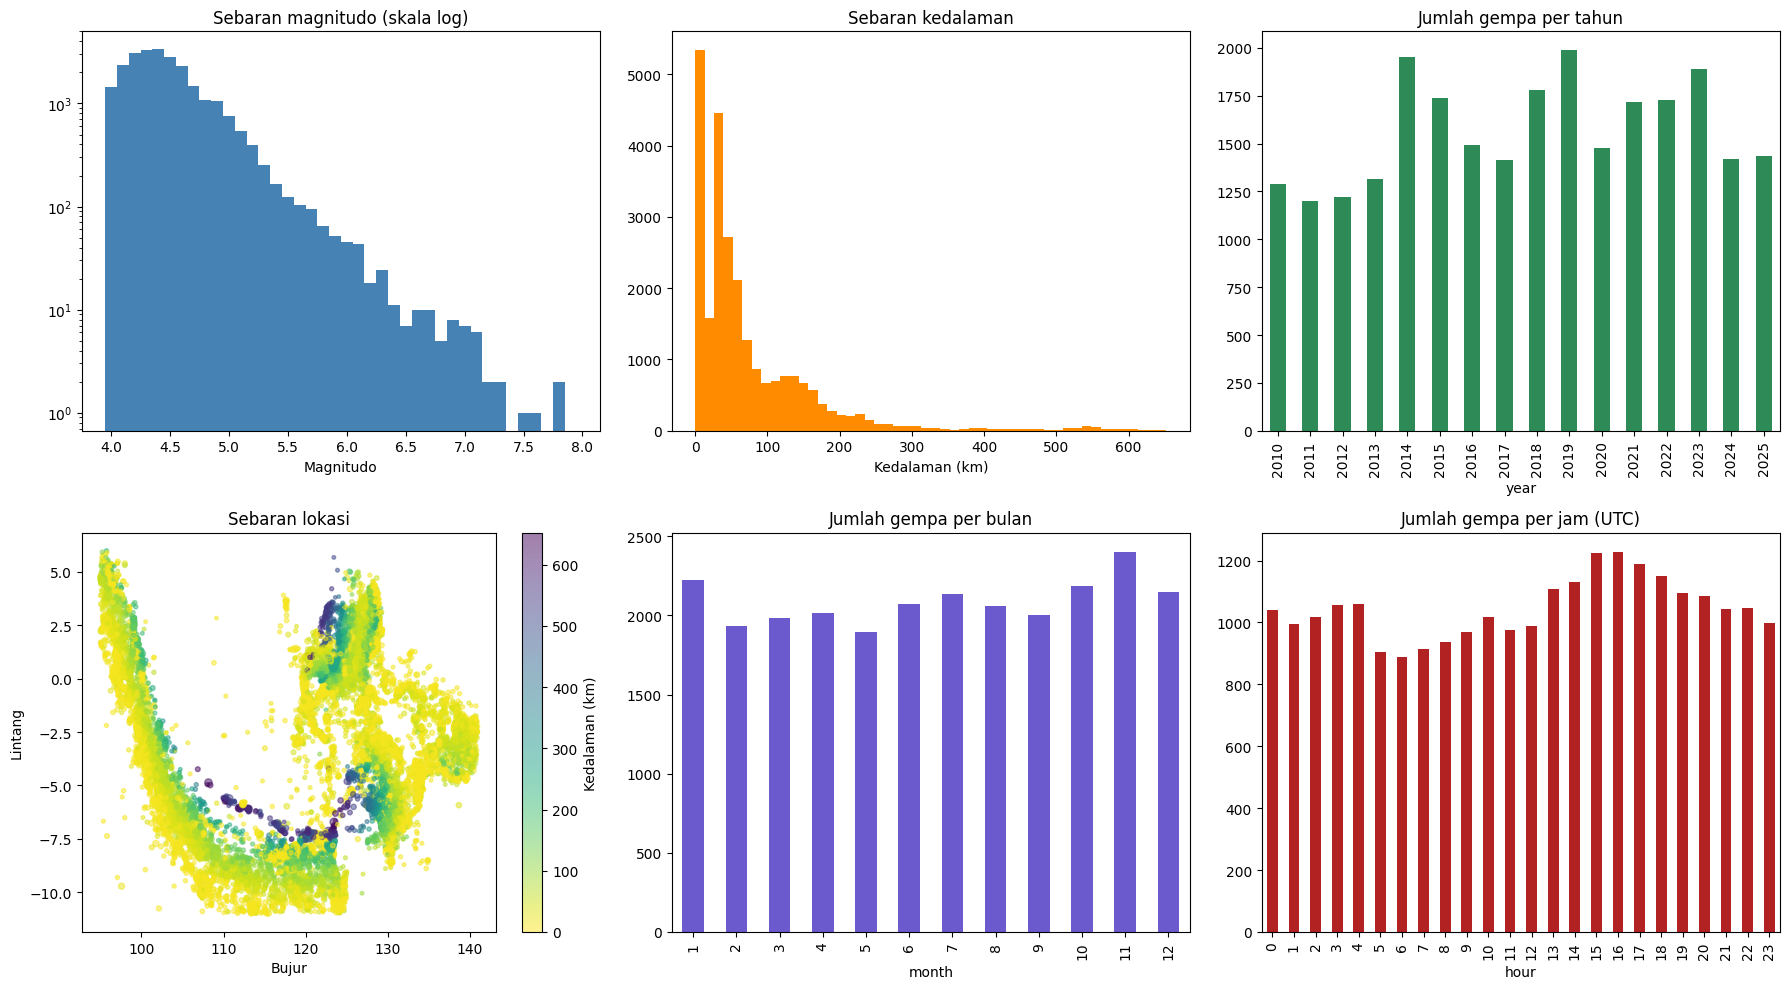

Korelasi depth-mag:
        depth    mag
depth  1.000 -0.094
mag   -0.094  1.000

Per kelompok kedalaman:
            count   mean
depth                   
(-1, 70]    16734  4.528
(70, 300]    7529  4.432
(300, 700]    794  4.437


In [8]:
df["year"] = df["time"].dt.year
df["month"] = df["time"].dt.month
df["hour"] = df["time"].dt.hour

fig, ax = plt.subplots(2, 3, figsize=(18, 10))
ax[0,0].hist(df["mag"], bins=np.arange(3.95, 8.05, 0.1), color="steelblue")
ax[0,0].set_yscale("log"); ax[0,0].set_title("Sebaran magnitudo (skala log)"); ax[0,0].set_xlabel("Magnitudo")
ax[0,1].hist(df["depth"], bins=50, color="darkorange")
ax[0,1].set_title("Sebaran kedalaman"); ax[0,1].set_xlabel("Kedalaman (km)")
df["year"].value_counts().sort_index().plot(kind="bar", ax=ax[0,2], color="seagreen")
ax[0,2].set_title("Jumlah gempa per tahun")
sc = ax[1,0].scatter(df["longitude"], df["latitude"], c=df["depth"], s=df["mag"]**3/10,
                     cmap="viridis_r", alpha=0.5)
plt.colorbar(sc, ax=ax[1,0], label="Kedalaman (km)")
ax[1,0].set_title("Sebaran lokasi"); ax[1,0].set_xlabel("Bujur"); ax[1,0].set_ylabel("Lintang")
df["month"].value_counts().sort_index().plot(kind="bar", ax=ax[1,1], color="slateblue")
ax[1,1].set_title("Jumlah gempa per bulan")
df["hour"].value_counts().sort_index().plot(kind="bar", ax=ax[1,2], color="firebrick")
ax[1,2].set_title("Jumlah gempa per jam (UTC)")
plt.tight_layout(); plt.show()

print("Korelasi depth-mag:\n", df[["depth", "mag"]].corr().round(3))
print("\nPer kelompok kedalaman:")
print(df.groupby(pd.cut(df["depth"], [-1, 70, 300, 700]), observed=True)["mag"].agg(["count", "mean"]).round(3))

### A. Magnitudo (histogram, skala log)
- **Temuan:** Sebaran sangat miring ke kanan; gempa besar jarang, dan katalog tampak tidak lengkap di bawah ≈ M 4,3.
- **Bukti:** Rata-rata 4,50, median 4,40, simpangan baku 0,39, maksimum 7,8. Pada skala log jumlah kejadian turun hampir lurus ke arah magnitudo besar, dengan puncak di sekitar M 4,3–4,5.
- **Interpretasi:** Pola ini khas hubungan frekuensi–magnitudo (Gutenberg–Richter). Puncak yang tidak berada di 4,0 menandakan deteksi gempa kecil belum lengkap.
- **Implikasi:** Magnitudo dipakai apa adanya (rentangnya kecil), tetapi ketidaklengkapan katalog dicatat; ambang M ≥ 4,3 atau 4,5 diuji di tahap lanjutan.

### B. Kedalaman (histogram)
- **Temuan:** Kedalaman sangat miring ke kanan; mayoritas gempa dangkal.
- **Bukti:** 66,8% dangkal (< 70 km; 16.734 kejadian), 30,0% menengah (7.529), 3,2% dalam (> 300 km; 794). Median 44,6 km, rata-rata 77,2 km. Lonjakan di 10 km (4.600 kejadian) dan 35 km (2.006).
- **Interpretasi:** Aktivitas seismik Indonesia didominasi gempa dangkal; gempa dalam jarang. Lonjakan di nilai bulat kemungkinan nilai bawaan USGS.
- **Implikasi:** Kedalaman ditransformasi `log1p` agar nilai ekstrem tidak mendominasi jarak. Nilai bawaan berpotensi membentuk pola semu dan dicatat sebagai keterbatasan.

### C. Lokasi (peta sebaran, warna = kedalaman)
- **Temuan:** Episentrum membentuk busur, dan gempa dalam terkonsentrasi di area tertentu.
- **Bukti:** Titik membentuk busur dari Sumatra, Jawa, Nusa Tenggara, Banda, hingga Sulawesi–Maluku dan Papua. Gempa dalam (ungu, > 300 km) mengumpul terutama di sekitar Laut Banda, Laut Flores, dan Laut Maluku, bukan tersebar merata.
- **Interpretasi:** Bentuk ini sesuai zona subduksi, dengan kedalaman bertambah menjauhi palung.
- **Implikasi:** Struktur spasial kuat, sehingga lintang, bujur, dan kedalaman menjadi fitur utama; untuk DBSCAN dipakai jarak haversine agar jarak dalam km.

### D. Waktu (per tahun dan per bulan)
- **Temuan:** Jumlah per tahun naik-turun tanpa tren konsisten; per bulan relatif merata.
- **Bukti:** Sekitar 1.200–2.000 kejadian per tahun dengan puncak 2014, 2019, dan 2023. Per bulan sekitar 1.900–2.400 (November tertinggi). Bulan-tahun terpadat: Januari 2023 (350), November 2014 (294), Juli 2019 (292), jauh di atas rata-rata ≈ 130.
- **Interpretasi:** Tidak tampak musim gempa. Karena jumlah tidak naik terus-menerus, perbaikan jaringan sensor saja bukan penjelasan yang cukup; lonjakan lebih mungkin terkait rangkaian gempa besar dan susulannya (dugaan, belum diuji di notebook ini).
- **Implikasi:** Kejadian tidak independen, sehingga uji statistik sederhana terlalu optimis. Fitur bulan diuji lewat ablasi fitur waktu (bagian 6).

### E. Hubungan kedalaman dan magnitudo
- **Temuan:** Hubungannya lemah.
- **Bukti:** Korelasi −0,094. Rata-rata magnitudo 4,53 (dangkal), 4,43 (menengah), 4,44 (dalam).
- **Interpretasi:** Kedalaman nyaris tidak menjelaskan besar gempa; selisih ≈ 0,1 kecil dibanding simpangan baku 0,39.
- **Implikasi:** Fitur-fitur relatif tidak redundan, sehingga PCA diperkirakan tidak banyak memampatkan dimensi (diuji di bagian 6).

### F. Uji pola jam: semua gempa vs M ≥ 5

In [9]:
for batas in [4.0, 5.0]:
    c = df[df["mag"] >= batas]["hour"].value_counts().reindex(range(24), fill_value=0)
    print(f"M>={batas}: n={c.sum()}, max/min={c.max()/max(c.min(),1):.2f}, p={chisquare(c).pvalue:.3g}")

print("\nBulan dengan gempa terbanyak:")
print(df.groupby(["year", "month"]).size().nlargest(8))

M>=4.0: n=25057, max/min=1.39, p=5.01e-30
M>=5.0: n=2749, max/min=1.33, p=0.922

Bulan dengan gempa terbanyak:
year  month
2023  1        350
2014  11       294
2019  7        292
2018  8        265
2019  11       260
2015  12       233
2023  11       228
2018  9        226
dtype: int64


- **Temuan:** Pola jam terlihat pada seluruh data, tetapi tidak signifikan pada gempa besar.
- **Bukti:** M ≥ 4: n = 25.057, rasio max/min 1,39, p = 5,01×10⁻³⁰. M ≥ 5: n = 2.749, rasio 1,33, p = 0,922. Dari grafik, jam terendah sekitar 05–07 UTC (≈ 890 kejadian) dan tertinggi sekitar 15–16 UTC (≈ 1.230).
- **Interpretasi:** Pola yang hilang pada gempa besar **mendukung dugaan bias deteksi** (gempa kecil lebih sulit tercatat saat derau aktivitas manusia tinggi), bukan bahwa gempa memilih jam. Namun data M ≥ 5 jauh lebih sedikit sehingga ujinya lebih lemah, dan kejadian tidak independen membuat p-value cenderung terlalu kecil. Jadi ini dugaan yang didukung, belum terbukti.
- **Implikasi:** Fitur jam dipakai dengan hati-hati dan diuji pengaruhnya lewat ablasi fitur (bagian 6.5). Dugaan diuji ulang dengan ambang magnitudo bertahap di tahap lanjutan.

### G. Ringkasan EDA dan keputusan desain

| Temuan EDA | Keputusan |
|---|---|
| Kedalaman sangat miring | Transformasi `log1p` |
| Fitur waktu bersifat siklik | Encoding sin/cos untuk bulan dan jam |
| Struktur spasial berbentuk busur | Fitur lintang, bujur; DBSCAN dengan jarak haversine |
| Kejadian tidak independen dan ada gempa susulan | Split berdasarkan waktu, bukan acak |
| Pola jam kemungkinan bias deteksi | Ablasi fitur waktu |
| Magnitudo dan kedalaman nyaris tidak berkorelasi | Perkiraan PCA tidak mereduksi banyak dimensi |

---
# 4. Preprocessing, Pembagian Data, dan Rekayasa Fitur Awal *(Komponen D dan E)*

## 4.1 Langkah Preprocessing

| No | Langkah | Alasan | Di mana |
|---|---|---|---|
| 1 | Hanya `type == "earthquake"` | Jenis kejadian lain bukan gempa | Bagian 2.2 (0 baris dibuang) |
| 2 | Buang duplikat `id` | Mencegah kejadian terhitung ganda | Bagian 2.1 (0 duplikat) |
| 3 | Buang kejadian negara tetangga lewat `place` | Fokus pada wilayah Indonesia | Bagian 2.2 (5.378 baris) |
| 4 | Pertahankan 7 kolom yang relevan | Kolom kualitas banyak kosong dan tidak dipakai | Bagian 2.2 |
| 5 | Ubah `time` ke UTC dan urutkan menurut waktu | Diperlukan untuk split kronologis dan jeda waktu | Bagian 2.2 |
| 6 | Tidak ada imputasi | Kolom inti tidak punya nilai kosong | Bagian 2.3 |
| 7 | Outlier tidak dibuang | Gempa besar (hingga M 7,8) adalah kejadian nyata, bukan galat | Bagian 3 |
| 8 | Split kronologis: latih 2010–2017, uji 2018–2025 | Split acak membuat struktur waktu dan gempa susulan bocor antar periode | Bagian 4.3 |
| 9 | `log1p(depth)` | Kedalaman sangat miring | Bagian 4.3 |
| 10 | Encoding sin/cos untuk bulan dan jam | Waktu bersifat siklik (Des dekat Jan; jam 23 dekat 0) | Bagian 4.3 |
| 11 | `StandardScaler` dan PCA di-*fit* hanya pada data latih | Mencegah kebocoran dari data uji | Bagian 4.3 dan 6.2 |

## 4.2 Pencegahan Data Leakage

| Risiko | Pencegahan |
|---|---|
| Scaler atau PCA mempelajari data uji | `fit` hanya di data latih; data uji hanya `transform` atau `predict` |
| Statistik fitur turunan dihitung dari seluruh data | Kepadatan per grid dan median jeda waktu dihitung hanya dari data latih; sel grid yang tidak ada di latih bernilai 0 pada data uji |
| Jeda waktu antar gempa melintasi batas latih–uji | Jeda dihitung dalam masing-masing periode; nilai kosong pertama diisi median jeda data latih |
| Label pembanding bocor ke fitur | Cluster yang dibandingkan dengan kelompok kedalaman dibentuk tanpa fitur kedalaman (bagian 7.1) |
| Pemilihan parameter memakai data uji | `K` dipilih dari data latih. **Catatan:** pemilihan `eps` DBSCAN mempertimbangkan konsistensi latih–uji, sehingga data uji ikut berpengaruh pada pilihan itu; ini dicatat sebagai keterbatasan dan diperbaiki di tahap lanjutan |
| `magType` dan `place` dipakai sebagai fitur | Tidak dipakai sebagai fitur pada Milestone 1 |

## 4.3 Rekayasa Fitur Awal

| Fitur | Dibentuk dari | Alasan |
|---|---|---|
| `lat`, `lon` | `latitude`, `longitude` | Menggambarkan **lokasi** episentrum |
| `log_depth` | `log1p(depth)` | Meredam kemiringan kedalaman |
| `mag` | `mag` | Menggambarkan **magnitudo** |
| `month_sin`, `month_cos` | bulan kejadian | Mengodekan bulan secara siklik (aspek **waktu**) |
| `hour_sin`, `hour_cos` | jam kejadian (UTC) | Mengodekan jam secara siklik (aspek **waktu**) |
| `log_dt` | log(1 + jeda jam dari gempa sebelumnya) | Menangkap **pengelompokan waktu** (gempa susulan dan deret gempa) |
| `log_density` | log(1 + jumlah gempa pada grid 1°×1° dari data latih) | Menangkap **kepadatan lokal** aktivitas gempa |

Empat himpunan fitur dibandingkan untuk menjawab pertanyaan analisis 3:

| Himpunan | Fitur | Jumlah |
|---|---|---|
| A_semua | seluruh fitur di atas | 10 |
| B_tanpa_siklik | lat, lon, log_depth, mag, log_dt, log_density | 6 |
| C_lokasi_dalam | lat, lon, log_depth | 3 |
| D_lokasi_dalam_mag | lat, lon, log_depth, mag | 4 |

**Dampak yang diharapkan:** `log1p` mencegah kedalaman ekstrem mendominasi jarak; encoding siklik membuat Desember dan Januari (atau jam 23 dan 0) berdekatan; `log_dt` dan `log_density` menambahkan informasi yang tidak ada di kolom asli. Perbandingan A–D menguji fitur mana yang benar-benar membawa struktur.

## 4.4 Eksekusi: Pembagian Data dan Pembentukan Fitur

In [10]:
train = df[df["year"] <= 2017].sort_values("time").reset_index(drop=True)
test  = df[df["year"] >= 2018].sort_values("time").reset_index(drop=True)
print("Train:", len(train), "| Test:", len(test))

def cell_id(d):
    return (np.floor(d["latitude"]).astype(int).astype(str) + "_" +
            np.floor(d["longitude"]).astype(int).astype(str))

cell_counts_train = cell_id(train).value_counts()
dt_median_train = (train["time"].diff().dt.total_seconds() / 3600).median()

def make_features(d):
    f = pd.DataFrame(index=d.index)
    f["lat"] = d["latitude"]
    f["lon"] = d["longitude"]
    f["log_depth"] = np.log1p(d["depth"])
    f["mag"] = d["mag"]
    f["month_sin"] = np.sin(2*np.pi*d["time"].dt.month/12)
    f["month_cos"] = np.cos(2*np.pi*d["time"].dt.month/12)
    f["hour_sin"] = np.sin(2*np.pi*d["time"].dt.hour/24)
    f["hour_cos"] = np.cos(2*np.pi*d["time"].dt.hour/24)
    dt = d["time"].diff().dt.total_seconds() / 3600
    f["log_dt"] = np.log1p(dt.fillna(dt_median_train))
    f["log_density"] = np.log1p(cell_id(d).map(cell_counts_train).fillna(0))
    return f

F_tr, F_te = make_features(train), make_features(test)

FEATURE_SETS = {
    "A_semua":          list(F_tr.columns),
    "B_tanpa_siklik":   ["lat", "lon", "log_depth", "mag", "log_dt", "log_density"],
    "C_lokasi_dalam":   ["lat", "lon", "log_depth"],
    "D_lokasi_dalam_mag": ["lat", "lon", "log_depth", "mag"],
}

def scaled(cols):
    sc = StandardScaler().fit(F_tr[cols])       # fit hanya di train
    return sc.transform(F_tr[cols]), sc.transform(F_te[cols]), sc

X_tr, X_te, _ = scaled(FEATURE_SETS["A_semua"])
print("Bentuk matriks fitur A (train/test):", X_tr.shape, X_te.shape)

Train: 11619 | Test: 13438
Bentuk matriks fitur A (train/test): (11619, 10) (13438, 10)


**Hasil:** data latih 11.619 kejadian (2010–2017) dan data uji 13.438 kejadian (2018–2025). Matriks fitur set A berukuran 11.619 × 10 (latih) dan 13.438 × 10 (uji).

**Implikasi:** seluruh model berikut dilatih pada data latih dan diuji pada periode setelahnya.

---
# 5. Rancangan Evaluasi *(Komponen G)*

| Pertanyaan | Jawaban untuk proyek ini |
|---|---|
| Bagaimana data dibagi? | Split kronologis: latih 2010–2017 (11.619), uji 2018–2025 (13.438). Dipilih karena kejadian gempa berkelompok dalam waktu, sehingga split acak membocorkan struktur antar periode. |
| Apa arti "data uji" pada proyek tanpa label? | Model dilatih di periode latih lalu diterapkan ke periode uji untuk menguji apakah **struktur yang ditemukan bertahan antar periode**, bukan untuk menghitung akurasi. |
| Apakah ada validation set terpisah? | Tidak. `K` dipilih dari metrik internal pada data latih; `eps` DBSCAN dipilih dari tabel latih dan uji (keterbatasan, lihat bagian 4.2). |
| Validasi apa yang dipakai? | (1) konsistensi metrik antara data latih dan uji; (2) stabilitas bootstrap (model dilatih ulang pada 80% data latih, 10 kali, dibandingkan dengan ARI); (3) *trustworthiness* untuk reduksi dimensi; (4) kesesuaian cluster dengan kelompok kedalaman (NMI dan ARI). |
| Metrik apa yang dipakai dan mengapa? | Lihat tabel metrik di bawah. Tidak ada akurasi karena tidak ada label. |
| Bagaimana mencegah data leakage? | Lihat tabel risiko pada bagian 4.2. |
| Apa keterbatasan evaluasi ini? | Metrik internal dihitung di ruang fitur masing-masing model sehingga perbandingan antar ruang fitur berbeda hanya indikatif; hanya satu pembagian waktu; kejadian tidak independen. |

| Metrik | Arti | Arah lebih baik |
|---|---|---|
| Silhouette (sampel 5.000) | Seberapa jelas suatu titik terpisah dari cluster lain | Lebih tinggi (maks 1) |
| Davies-Bouldin | Rata-rata kemiripan cluster dengan cluster terdekatnya | Lebih rendah |
| Calinski-Harabasz | Rasio sebaran antar-cluster terhadap dalam-cluster | Lebih tinggi |
| Silhouette geografis (jarak haversine, titik non-noise) | Silhouette di ruang lintang–bujur untuk DBSCAN | Lebih tinggi |
| Jumlah cluster, % noise, % cluster terbesar | Gambaran struktur DBSCAN | Dibaca bersama silhouette |
| Adjusted Rand Index (ARI) | Kesamaan dua pengelompokan (stabilitas bootstrap; kesesuaian dengan kelompok kedalaman); bukan penilai kualitas cluster | Mendekati 1 = sama |
| NMI | Informasi bersama antara cluster dan kelompok kedalaman | Mendekati 1 = berkaitan kuat |
| Trustworthiness (k = 10) | Seberapa baik tetangga terdekat dipertahankan setelah reduksi ke 2D | Lebih tinggi (maks 1) |

---
# 6. Baseline dan Model Kandidat *(Komponen F)*

## 6.1 Baseline dan Kandidat

| Peran | Model | Konfigurasi | Alasan pemilihan |
|---|---|---|---|
| **Baseline** | K-Means | Semua fitur terstandardisasi (set A), tanpa reduksi dimensi, k = `K` | Acuan paling sederhana untuk proyek unsupervised |
| **Kandidat 1** | PCA + K-Means | PCA mempertahankan ≥ 90% variansi, lalu K-Means | Menguji apakah reduksi dimensi memperbaiki clustering |
| **Kandidat 2** | K-Means | Lokasi + kedalaman saja (set C) | Menguji apakah struktur ada di fitur spasial |
| **Kandidat 3** | Gaussian Mixture | Kovariansi penuh pada ruang PCA | Model probabilistik; berbeda dari pendekatan berbasis jarak |
| **Kandidat 4** | DBSCAN | Lintang–bujur, jarak haversine, `min_samples = 30`, `eps` 15–50 km | Berbasis kepadatan; cocok untuk bentuk busur dan menyisakan noise |
| **Pembanding reduksi** | PCA 2D, t-SNE, UMAP | Sampel 3.000 titik, trustworthiness | Membandingkan kualitas reduksi dimensi |
| **Eksperimen fitur** | K-Means pada set A–D | k = `K` | Menguji fitur mana yang membawa struktur (ablasi) |
| **Perbandingan ruang sama** | Baseline dan semua kandidat K-Means/GMM | Metrik dihitung di ruang A dan ruang C yang sama untuk semua model | Menutup keterbatasan metrik yang dihitung di ruang berbeda (bagian 6.9) |

## 6.2 Reduksi Dimensi: PCA (di-*fit* pada data latih)

Variansi per PC: [0.139 0.124 0.111 0.103 0.099 0.095 0.093 0.091 0.082 0.063]
Kumulatif      : [0.139 0.263 0.374 0.477 0.576 0.672 0.765 0.855 0.937 1.   ]
Jumlah PC untuk 90% variansi: 9 dari 10
              PC1   PC2   PC3
lat          0.45 -0.34  0.36
lon          0.50  0.23 -0.26
log_depth    0.23  0.59  0.00
mag         -0.13 -0.34  0.46
month_sin    0.00  0.28  0.25
month_cos    0.12 -0.34 -0.15
hour_sin     0.00  0.07  0.51
hour_cos     0.03 -0.02 -0.05
log_dt      -0.06  0.39  0.49
log_density  0.68 -0.11  0.11


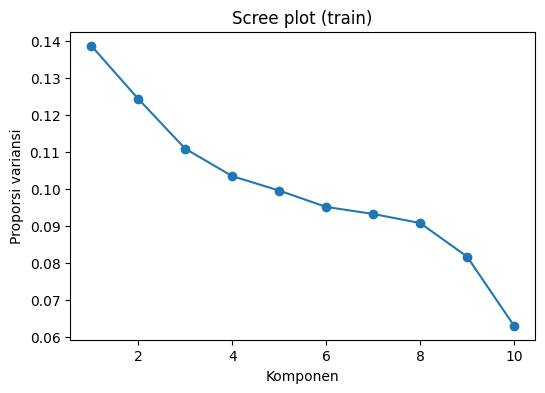

In [11]:
pca_full = PCA().fit(X_tr)
ev = pca_full.explained_variance_ratio_
n_pc90 = int(np.argmax(ev.cumsum() >= 0.90) + 1)
print("Variansi per PC:", np.round(ev, 3))
print("Kumulatif      :", np.round(ev.cumsum(), 3))
print("Jumlah PC untuk 90% variansi:", n_pc90, "dari", X_tr.shape[1])
print(pd.DataFrame(pca_full.components_[:3].T, index=FEATURE_SETS["A_semua"],
                   columns=["PC1", "PC2", "PC3"]).round(2))

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(ev)+1), ev, "o-"); plt.xlabel("Komponen"); plt.ylabel("Proporsi variansi")
plt.title("Scree plot (train)"); plt.show()

pca90 = PCA(n_components=n_pc90).fit(X_tr)
Z_tr, Z_te = pca90.transform(X_tr), pca90.transform(X_te)

- **Temuan:** PCA hampir tidak mereduksi dimensi.
- **Bukti:** 9 dari 10 komponen dibutuhkan untuk 90% variansi (kumulatif 85,5% pada PC ke-8 dan 93,7% pada PC ke-9). Variansi per komponen hampir merata: PC1 13,9% sampai PC10 6,3%, tanpa "siku" jelas pada scree plot.
- **Interpretasi:** Fitur-fitur relatif independen; tidak ada beberapa arah dominan yang dapat meringkas data. PC1 didominasi `log_density` (0,68), `lon` (0,50), dan `lat` (0,45), yaitu dimensi lokasi dan kepadatan. PC2 didominasi `log_depth` (0,59) disertai `log_dt` (0,39). PC3 dipengaruhi `hour_sin` (0,51), `log_dt` (0,49), dan `mag` (0,46). `hour_cos` hampir tidak berkontribusi.
- **Implikasi:** PCA tidak berguna untuk menyederhanakan fitur di sini, tetapi hasilnya informatif: struktur tidak terkonsentrasi pada sedikit arah. Ini sejalan dengan clustering yang lemah pada semua fitur (bagian 6.4).

## 6.3 Pemilihan Jumlah Cluster (hanya pada data latih)

In [12]:
def sweep(X, nama, ks=range(2, 11)):
    rows = []
    for k in ks:
        km = KMeans(k, n_init=10, random_state=SEED).fit(X)
        rows.append(dict(set=nama, k=k, inertia=km.inertia_,
                         silhouette=silhouette_score(X, km.labels_, sample_size=min(SIL_SAMPLE, len(X)), random_state=SEED),
                         davies_bouldin=davies_bouldin_score(X, km.labels_)))
    return pd.DataFrame(rows)

sw = pd.concat([sweep(X_tr, "A_semua"), sweep(scaled(FEATURE_SETS["C_lokasi_dalam"])[0], "C_lokasi_dalam")])
print(sw.round(3).to_string(index=False))

           set  k    inertia  silhouette  davies_bouldin
       A_semua  2 103946.979       0.111           2.857
       A_semua  3  97180.562       0.104           2.581
       A_semua  4  91391.674       0.099           2.604
       A_semua  5  87596.880       0.094           2.502
       A_semua  6  83999.377       0.095           2.347
       A_semua  7  81304.299       0.090           2.248
       A_semua  8  78952.533       0.093           2.352
       A_semua  9  76913.479       0.093           2.187
       A_semua 10  74734.494       0.095           2.184
C_lokasi_dalam  2  24489.691       0.343           1.371
C_lokasi_dalam  3  17295.237       0.379           1.060
C_lokasi_dalam  4  13338.573       0.383           0.964
C_lokasi_dalam  5   9927.415       0.402           0.894
C_lokasi_dalam  6   8575.755       0.401           0.895
C_lokasi_dalam  7   7525.470       0.407           0.932
C_lokasi_dalam  8   6455.708       0.407           0.882
C_lokasi_dalam  9   5704.361   

In [13]:
K = 5
print("K =", K)

K = 5


**Alasan memilih `K = 5`:**
- **Temuan:** Pada set C, inertia turun tajam hingga k = 5 lalu melandai; silhouette mendatar sekitar 0,40.
- **Bukti:** Inertia set C 13.339 (k = 4) → 9.927 (k = 5), turun 25,6%; lalu 8.576 (k = 6), turun 13,6%. Silhouette set C: 0,402 (k = 5), 0,401 (k = 6), 0,410 (k = 10). Pada set A silhouette hanya 0,090–0,111 untuk semua k (tertinggi k = 2) dan Davies-Bouldin cenderung turun seiring k (2,857 pada k = 2 menjadi 2,184 pada k = 10).
- **Interpretasi:** Menambah cluster di atas 5 tidak memberi peningkatan berarti pada set C; pada set A tidak ada k yang jelas unggul.
- **Implikasi:** `K = 5` dipakai untuk semua model agar perbandingan adil. Sensitivitas terhadap k belum dikaji menyeluruh (rencana setelah UTS).

## 6.4 Baseline dan Kandidat K-Means dan GMM

Silhouette, Davies-Bouldin, dan Calinski-Harabasz dihitung pada data latih dan data uji (label uji diperoleh dengan `predict`).

In [14]:
results = []

def cluster_metrics(X, labels):
    if len(np.unique(labels)) < 2:
        return dict(silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan)
    return dict(
        silhouette=silhouette_score(X, labels, sample_size=min(SIL_SAMPLE, len(X)), random_state=SEED),
        davies_bouldin=davies_bouldin_score(X, labels),
        calinski_harabasz=calinski_harabasz_score(X, labels))

def log_result(model, fitur, param, Xtr_, Xte_, lab_tr, lab_te, peran):
    for split, X_, lab in [("train", Xtr_, lab_tr), ("test", Xte_, lab_te)]:
        results.append(dict(peran=peran, model=model, fitur=fitur, parameter=param,
                            validasi="split waktu (fit 2010-17, uji 2018-25)", split=split,
                            **cluster_metrics(X_, lab)))

# --- Baseline ---
km = KMeans(K, n_init=10, random_state=SEED).fit(X_tr)
log_result("K-Means", "A_semua (10 fitur)", f"k={K}", X_tr, X_te, km.labels_, km.predict(X_te), "baseline")

# --- Kandidat 1: PCA + K-Means ---
km = KMeans(K, n_init=10, random_state=SEED).fit(Z_tr)
log_result("PCA + K-Means", f"A_semua -> {n_pc90} PC", f"k={K}", Z_tr, Z_te, km.labels_, km.predict(Z_te), "kandidat")

# --- Kandidat 2: K-Means lokasi + kedalaman ---
C_tr, C_te, _ = scaled(FEATURE_SETS["C_lokasi_dalam"])
km = KMeans(K, n_init=10, random_state=SEED).fit(C_tr)
log_result("K-Means", "C_lokasi_dalam (3 fitur)", f"k={K}", C_tr, C_te, km.labels_, km.predict(C_te), "kandidat")

# --- Kandidat 3: GMM di ruang PCA ---
gmm = GaussianMixture(K, covariance_type="full", n_init=3, random_state=SEED).fit(Z_tr)
log_result("GMM", f"A_semua -> {n_pc90} PC", f"k={K}", Z_tr, Z_te, gmm.predict(Z_tr), gmm.predict(Z_te), "kandidat")

hasil_sementara = pd.DataFrame(results)
print(hasil_sementara.round(3).to_string(index=False))

   peran         model                    fitur parameter                               validasi split  silhouette  davies_bouldin  calinski_harabasz
baseline       K-Means       A_semua (10 fitur)       k=5 split waktu (fit 2010-17, uji 2018-25) train       0.094           2.502            947.757
baseline       K-Means       A_semua (10 fitur)       k=5 split waktu (fit 2010-17, uji 2018-25)  test       0.088           2.570           1128.077
kandidat PCA + K-Means          A_semua -> 9 PC       k=5 split waktu (fit 2010-17, uji 2018-25) train       0.101           2.334           1023.041
kandidat PCA + K-Means          A_semua -> 9 PC       k=5 split waktu (fit 2010-17, uji 2018-25)  test       0.093           2.470           1121.693
kandidat       K-Means C_lokasi_dalam (3 fitur)       k=5 split waktu (fit 2010-17, uji 2018-25) train       0.402           0.894           7291.232
kandidat       K-Means C_lokasi_dalam (3 fitur)       k=5 split waktu (fit 2010-17, uji 2018-25)  te

**Hasil (silhouette, k = 5):**

| Model | Fitur | Latih | Uji |
|---|---|---|---|
| Baseline K-Means | 10 fitur (A) | 0,094 | 0,088 |
| PCA (9 PC) + K-Means | 10 fitur → 9 PC | 0,101 | 0,093 |
| GMM | 9 PC | 0,076 | 0,072 |
| K-Means | lokasi + kedalaman (C) | 0,402 | 0,417 |

- **Temuan:** Perbedaan besar datang dari pemilihan fitur, bukan dari pemilihan model.
- **Bukti:** PCA+K-Means hanya 0,007 di atas baseline (Davies-Bouldin 2,334 vs 2,502 di data latih); GMM lebih rendah dari baseline. Set C memberi silhouette sekitar empat kali lipat baseline (0,402 vs 0,094; Davies-Bouldin 0,894 vs 2,502).
- **Interpretasi:** Selisih sekecil itu tidak cukup untuk menyatakan PCA memperbaiki clustering, sesuai hasil PCA yang hampir tidak mereduksi dimensi. Silhouette ≈ 0,1 menunjukkan struktur sangat lemah pada semua fitur, bukan kegagalan model: gempa membentuk busur menerus, bukan gerombol terpisah.
- **Implikasi:** Struktur kuat ada pada lokasi dan kedalaman. Metrik dihitung di ruang fitur masing-masing, sehingga perbandingan antar ruang fitur hanya indikatif (bagian 6.9 mengulang perbandingan di ruang yang sama).

## 6.5 Eksperimen Himpunan Fitur (ablasi fitur waktu)

In [15]:
rows = []
for nama, cols in FEATURE_SETS.items():
    a, b, _ = scaled(cols)
    km = KMeans(K, n_init=10, random_state=SEED).fit(a)
    for split, X_, lab in [("train", a, km.labels_), ("test", b, km.predict(b))]:
        m = cluster_metrics(X_, lab)
        rows.append(dict(set_fitur=nama, jumlah_fitur=len(cols), split=split, **m))
        results.append(dict(peran="eksperimen set fitur", model="K-Means", fitur=nama, parameter=f"k={K}",
                            validasi="split waktu (fit 2010-17, uji 2018-25)", split=split, **m))
cmp_fitur = pd.DataFrame(rows)
print(cmp_fitur.round(3).to_string(index=False))

         set_fitur  jumlah_fitur split  silhouette  davies_bouldin  calinski_harabasz
           A_semua            10 train       0.094           2.502            947.757
           A_semua            10  test       0.088           2.570           1128.077
    B_tanpa_siklik             6 train       0.185           1.637           1982.999
    B_tanpa_siklik             6  test       0.188           1.628           2228.525
    C_lokasi_dalam             3 train       0.402           0.894           7291.232
    C_lokasi_dalam             3  test       0.417           0.894           8485.844
D_lokasi_dalam_mag             4 train       0.292           1.150           3644.414
D_lokasi_dalam_mag             4  test       0.283           1.193           4009.879


- **Temuan:** Fitur waktu siklik tidak membawa struktur, melainkan derau.
- **Bukti (silhouette latih → uji):** A 0,094 → 0,088; B (tanpa waktu siklik) 0,185 → 0,188; C 0,402 → 0,417; D (C + magnitudo) 0,292 → 0,283. Davies-Bouldin: A 2,502, B 1,637, C 0,894, D 1,150 (data latih).
- **Interpretasi:** Membuang fitur waktu siklik menggandakan silhouette, dan menambah magnitudo ke set C menurunkannya (0,402 → 0,292), jadi magnitudo juga tidak membentuk kelompok yang jelas bersama lokasi dan kedalaman. Nilai uji mendekati nilai latih pada semua himpunan, sehingga strukturnya stabil antar periode.
- **Implikasi:** Menjawab pertanyaan analisis 3: tidak ada bukti bahwa bulan dan jam membentuk cluster bermakna (ini bukan bukti bahwa pola waktu tidak ada sama sekali). Perbandingan ini hanya indikatif karena ruang fitur berbeda.

## 6.6 DBSCAN Geografis

DBSCAN pada (lintang, bujur) dengan jarak haversine sehingga `eps` dinyatakan dalam km. DBSCAN tidak punya `predict`, jadi data latih dan uji di-*fit* terpisah lalu dibandingkan strukturnya.

In [16]:
def dbscan_run(d, eps_km, min_samples=30):
    coords = np.radians(d[["latitude", "longitude"]].values)
    lab = DBSCAN(eps=eps_km/6371.0, min_samples=min_samples,
                 algorithm="ball_tree", metric="haversine").fit(coords).labels_
    return coords, lab

def sil_geo(coords, lab):
    m = lab >= 0
    if len(np.unique(lab[m])) < 2:
        return np.nan
    return silhouette_score(coords[m], lab[m], metric="haversine",
                            sample_size=min(SIL_SAMPLE, m.sum()), random_state=SEED)

rows = []
for eps_km in [15, 25, 40, 50]:
    for nama, d in [("train", train), ("test", test)]:
        coords, lab = dbscan_run(d, eps_km)
        ukuran = pd.Series(lab[lab >= 0]).value_counts()
        rows.append(dict(eps_km=eps_km, split=nama, n_cluster=len(ukuran),
                         noise_pct=round((lab == -1).mean()*100, 1),
                         cluster_terbesar_pct=round(ukuran.max()/len(lab)*100, 1) if len(ukuran) else 0,
                         silhouette_geo=sil_geo(coords, lab)))
        results.append(dict(peran="kandidat", model="DBSCAN (haversine)", fitur="lintang, bujur",
                            parameter=f"eps={eps_km} km, min_samples=30; n_cluster={len(ukuran)}, noise={(lab==-1).mean()*100:.1f}%",
                            validasi="fit terpisah train vs test", split=nama,
                            silhouette=sil_geo(coords, lab), davies_bouldin=np.nan, calinski_harabasz=np.nan))
db_tab = pd.DataFrame(rows)
print(db_tab.round(3).to_string(index=False))

 eps_km split  n_cluster  noise_pct  cluster_terbesar_pct  silhouette_geo
     15 train         26       74.0                   6.1           0.655
     15  test         29       68.0                   7.7           0.551
     25 train         32       53.1                  13.2           0.609
     25  test         38       48.1                  14.8           0.511
     40 train         41       26.1                  24.3           0.262
     40  test         39       22.8                  26.2           0.447
     50 train         21       16.6                  26.2           0.353
     50  test         25       15.8                  28.0           0.317


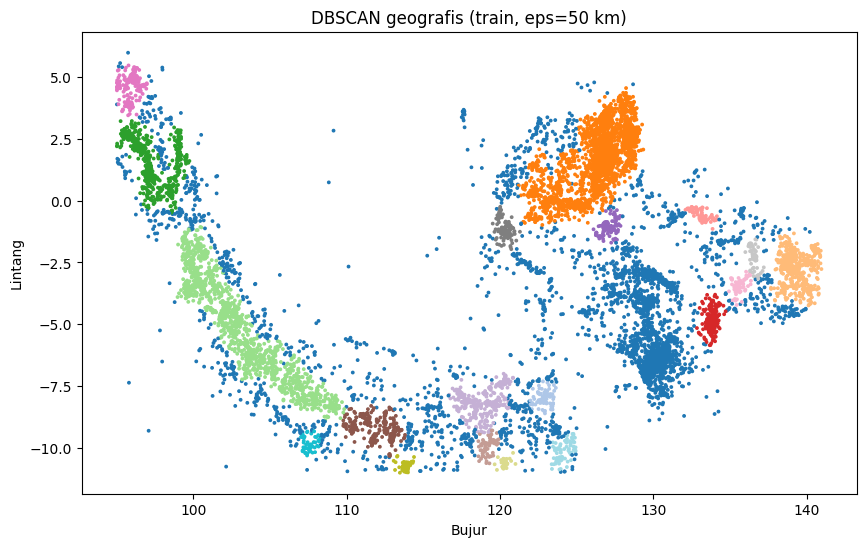

               n    lat     lon  depth_median  mag_mean  mag_max
cluster_db                                                      
2           3045   1.62  126.30         58.22      4.48      7.1
0           1971  -5.36  129.77        105.20      4.44      7.1
5           1402  -5.14  103.20         41.64      4.59      7.8
4            759   1.59   97.23         35.00      4.51      7.8
3            575  -2.72  139.37         36.40      4.51      7.0
9            320  -8.17  118.81        135.00      4.42      6.3
10           257  -9.22  111.87         51.54      4.47      5.9
6            215  -4.85  133.81         17.38      4.52      7.0
12           198   4.61   95.91         43.80      4.59      7.2
14           131  -1.16  120.33         27.00      4.52      6.6
8            128  -1.07  127.03         35.15      4.52      6.3
16           111 -10.76  113.84         10.00      4.54      6.1
7             88  -0.58  133.13         35.00      4.45      5.8
1             80  -8.00  

In [17]:
EPS_KM = 50
coords_tr, lab_tr = dbscan_run(train, EPS_KM)
train["cluster_db"] = lab_tr

plt.figure(figsize=(10, 6))
plt.scatter(train["longitude"], train["latitude"], c=lab_tr, s=3, cmap="tab20")
plt.title(f"DBSCAN geografis (train, eps={EPS_KM} km)"); plt.xlabel("Bujur"); plt.ylabel("Lintang"); plt.show()

profil = (train[train["cluster_db"] >= 0].groupby("cluster_db")
          .agg(n=("mag", "size"), lat=("latitude", "mean"), lon=("longitude", "mean"),
               depth_median=("depth", "median"), mag_mean=("mag", "mean"), mag_max=("mag", "max"))
          .round(2).sort_values("n", ascending=False))
print(profil)

**Tabel penyetelan `eps`** (`min_samples = 30`):

| eps (km) | cluster latih / uji | noise latih / uji (%) | cluster terbesar latih / uji (%) | silhouette geo latih / uji |
|---|---|---|---|---|
| 15 | 26 / 29 | 74,0 / 68,0 | 6,1 / 7,7 | 0,655 / 0,551 |
| 25 | 32 / 38 | 53,1 / 48,1 | 13,2 / 14,8 | 0,609 / 0,511 |
| 40 | 41 / 39 | 26,1 / 22,8 | 24,3 / 26,2 | 0,262 / 0,447 |
| 50 | 21 / 25 | 16,6 / 15,8 | 26,2 / 28,0 | 0,353 / 0,317 |

- **Temuan:** `eps = 50 km` memberi keseimbangan terbaik antara noise dan konsistensi antar periode; peta mengikuti busur subduksi.
- **Bukti:** Pada eps kecil silhouette tinggi tetapi 74% (eps 15) dan 53% (eps 25) titik menjadi noise, sehingga hanya sisanya yang dinilai. Eps 40 km tidak konsisten antar periode (0,262 vs 0,447). Eps 50 km memberi noise terendah (16,6% dan 15,8%) dan selisih silhouette latih–uji terkecil (0,036). Cluster terbesar mencapai 26–28% data.
- **Interpretasi:** Pada eps 50 km zona memanjang seperti busur Sumatra–Jawa menyatu menjadi satu cluster panjang (efek *chaining*), sehingga cluster besar tidak berarti zona seragam. Silhouette jangan dibaca sendirian karena hanya menilai titik non-noise.
- **Implikasi:** `EPS_KM = 50` dipakai sementara. `min_samples` belum disetel dan pemilihan eps memakai informasi data uji (lihat bagian 4.2); keduanya diperbaiki di tahap lanjutan.

**Profil cluster terbesar** (data latih, eps 50 km; wilayah diperkirakan dari koordinat pusat, cocokkan dengan peta):

| Cluster | n | Pusat (lintang, bujur) | Median kedalaman | Perkiraan wilayah |
|---|---|---|---|---|
| 2 | 3.045 | 1,6; 126,3 | 58 km | Laut Maluku, Halmahera, Sulawesi Utara |
| 0 | 1.971 | −5,4; 129,8 | 105 km | Laut Banda (zona menengah–dalam) |
| 5 | 1.402 | −5,1; 103,2 | 42 km | Sumatra tengah–selatan hingga Jawa bagian barat (memanjang) |
| 4 | 759 | 1,6; 97,2 | 35 km | Sumatra bagian utara |
| 3 | 575 | −2,7; 139,4 | 36 km | Papua bagian utara |
| 9 | 320 | −8,2; 118,8 | 135 km | Nusa Tenggara (Sumbawa–Flores) |
| 10 | 257 | −9,2; 111,9 | 52 km | Selatan Jawa bagian timur |
| 1 | 80 | −8,0; 122,9 | 213 km | Flores–Banda bagian barat (cluster paling dalam) |

Kedalaman median berbeda tajam antar cluster (10 km sampai 213 km), sehingga cluster berdasarkan lokasi memang membedakan zona dangkal dan zona dalam.

## 6.7 Stabilitas Cluster (bootstrap)
Model dilatih ulang pada 80% data latih yang diambil acak (10 kali), lalu label seluruh data latih dibandingkan dengan model acuan memakai ARI.

In [18]:
def stabilitas(Xtr_, k, n_rep=10):
    ref = KMeans(k, n_init=10, random_state=SEED).fit(Xtr_)
    ref_lab = ref.predict(Xtr_)
    rng = np.random.RandomState(SEED)
    aris = []
    for i in range(n_rep):
        idx = rng.choice(len(Xtr_), int(0.8*len(Xtr_)), replace=False)
        m = KMeans(k, n_init=10, random_state=i).fit(Xtr_[idx])
        aris.append(adjusted_rand_score(ref_lab, m.predict(Xtr_)))
    return np.mean(aris), np.std(aris)

for nama, Xs in [("A_semua", X_tr), ("C_lokasi_dalam", C_tr)]:
    mu, sd = stabilitas(Xs, K)
    print(f"{nama:16s} k={K}  ARI = {mu:.3f} ± {sd:.3f}")
    results.append(dict(peran="stabilitas", model="K-Means", fitur=nama, parameter=f"k={K}",
                        validasi="bootstrap 80% x10 (ARI)", split="train",
                        silhouette=np.nan, davies_bouldin=np.nan, calinski_harabasz=np.nan,
                        ARI_mean=mu, ARI_std=sd))

A_semua          k=5  ARI = 0.630 ± 0.146
C_lokasi_dalam   k=5  ARI = 0.994 ± 0.002


- **Temuan:** Struktur pada set C sangat stabil, sedangkan pada set A tidak.
- **Bukti:** ARI set A 0,630 ± 0,146; set C 0,994 ± 0,002.
- **Interpretasi:** Cluster dari semua fitur berubah-ubah mengikuti sampel data (konsisten dengan silhouette rendah), sedangkan cluster lokasi + kedalaman hampir identik di setiap sampel.
- **Implikasi:** Mendukung kesimpulan bahwa struktur yang nyata ada pada lokasi dan kedalaman.

## 6.8 Evaluasi Reduksi Dimensi: PCA vs t-SNE vs UMAP
Trustworthiness (0–1) pada sampel 3.000 titik data latih. t-SNE dan UMAP tidak digunakan untuk data uji (t-SNE tidak punya `transform`).

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


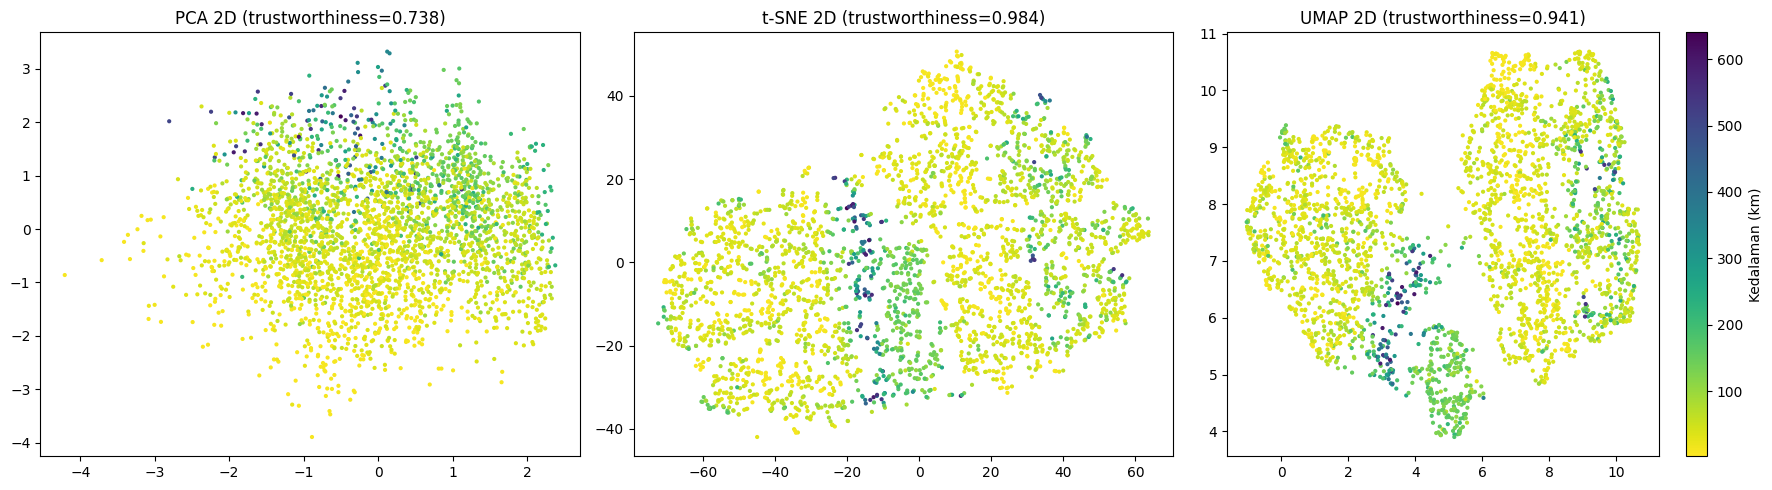

In [19]:
rng = np.random.RandomState(SEED)
idx = rng.choice(len(X_tr), 3000, replace=False)
Xs_ = X_tr[idx]
emb = {}
emb["PCA 2D"] = PCA(n_components=2, random_state=SEED).fit_transform(Xs_)
emb["t-SNE 2D"] = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(Xs_)
try:
    import umap
    emb["UMAP 2D"] = umap.UMAP(n_components=2, random_state=SEED).fit_transform(Xs_)
except ImportError:
    print("UMAP tidak terpasang (pip install umap-learn) -> dilewati")

fig, axs = plt.subplots(1, len(emb), figsize=(6*len(emb), 5))
axs = np.atleast_1d(axs)
for a, (nama, E) in zip(axs, emb.items()):
    t = trustworthiness(Xs_, E, n_neighbors=10)
    s = a.scatter(E[:, 0], E[:, 1], c=train["depth"].values[idx], s=4, cmap="viridis_r")
    a.set_title(f"{nama} (trustworthiness={t:.3f})")
    results.append(dict(peran="reduksi dimensi", model=nama, fitur="A_semua (10 fitur)",
                        parameter="n_neighbors=10, sampel 3000", validasi="trustworthiness (train)",
                        split="train", silhouette=np.nan, davies_bouldin=np.nan,
                        calinski_harabasz=np.nan, trustworthiness=t))
plt.colorbar(s, ax=axs[-1], label="Kedalaman (km)"); plt.tight_layout(); plt.show()

- **Temuan:** t-SNE dan UMAP jauh lebih baik menjaga tetangga terdekat dibanding PCA 2D.
- **Bukti:** Trustworthiness PCA 2D 0,738; UMAP 0,941; t-SNE 0,984. Pada UMAP tampak dua kelompok besar dan kelompok kecil, dan gempa dalam (> 300 km) mengumpul di area kecil.
- **Interpretasi:** Struktur data bersifat non-linear sehingga proyeksi linear 2D kehilangan banyak informasi tetangga. Gumpalan t-SNE tidak membentuk pemisahan tegas, selaras dengan silhouette yang rendah pada semua fitur.
- **Implikasi:** t-SNE dan UMAP dipakai untuk visualisasi, bukan sebagai pengganti fitur untuk clustering.

## 6.9 Perbandingan di Ruang Evaluasi yang Sama

Pada bagian 6.4–6.5 silhouette dihitung di ruang fitur masing-masing model, sehingga angka antar ruang hanya indikatif. Di sini label cluster setiap model (dilatih seperti sebelumnya, hanya pada data latih) dinilai ulang di **dua ruang yang sama**: ruang A (10 fitur terstandardisasi) dan ruang C (lintang, bujur, log kedalaman terstandardisasi). Tidak ada model yang dilatih ulang dengan data uji; hanya tempat metrik dihitung yang disamakan.


In [20]:
def fit_labels(Xa, Xb, kind="km"):
    if kind == "km":
        m = KMeans(K, n_init=10, random_state=SEED).fit(Xa)
    else:
        m = GaussianMixture(K, covariance_type="full", n_init=3, random_state=SEED).fit(Xa)
    return m.predict(Xa), m.predict(Xb)

B_tr, B_te, _ = scaled(FEATURE_SETS["B_tanpa_siklik"])
D_tr, D_te, _ = scaled(FEATURE_SETS["D_lokasi_dalam_mag"])
modelsets = [
    ("Baseline K-Means",   "A_semua (10 fitur)",       X_tr, X_te, "km"),
    ("PCA + K-Means",      f"A -> {n_pc90} PC",        Z_tr, Z_te, "km"),
    ("GMM",                f"A -> {n_pc90} PC",        Z_tr, Z_te, "gmm"),
    ("K-Means",            "B_tanpa_siklik (6)",       B_tr, B_te, "km"),
    ("K-Means",            "C_lokasi_dalam (3)",       C_tr, C_te, "km"),
    ("K-Means",            "D_lokasi_dalam_mag (4)",   D_tr, D_te, "km"),
]
SPACES = {"ruang_A": (X_tr, X_te), "ruang_C": (C_tr, C_te)}

rows = []
for nama, fitur, Xa, Xb, kind in modelsets:
    l_tr, l_te = fit_labels(Xa, Xb, kind)
    for rname, (Sa, Sb) in SPACES.items():
        for split, S, lab in [("train", Sa, l_tr), ("test", Sb, l_te)]:
            m = cluster_metrics(S, lab)
            rows.append(dict(model=nama, fitur=fitur, ruang=rname, split=split, **m))
            results.append(dict(peran="perbandingan ruang sama", model=nama, fitur=fitur,
                                parameter=f"k={K}; metrik dihitung di {rname}",
                                validasi="split waktu (fit 2010-17, uji 2018-25)", split=split, **m))
tab_ruang = pd.DataFrame(rows)
for met in ["silhouette", "davies_bouldin"]:
    print(f"\n{met} (baris = model; kolom = ruang evaluasi / split)")
    print(tab_ruang.pivot_table(index=["model", "fitur"], columns=["ruang", "split"], values=met,
                                sort=False).round(3).to_string())



silhouette (baris = model; kolom = ruang evaluasi / split)
ruang                                   ruang_A        ruang_C       
split                                     train   test   train   test
model            fitur                                               
Baseline K-Means A_semua (10 fitur)       0.094  0.088   0.158  0.160
PCA + K-Means    A -> 9 PC                0.095  0.086   0.080  0.027
GMM              A -> 9 PC                0.072  0.067  -0.008 -0.027
K-Means          B_tanpa_siklik (6)       0.096  0.101   0.209  0.194
                 C_lokasi_dalam (3)       0.088  0.095   0.402  0.417
                 D_lokasi_dalam_mag (4)   0.091  0.088   0.263  0.229

davies_bouldin (baris = model; kolom = ruang evaluasi / split)
ruang                                   ruang_A        ruang_C        
split                                     train   test   train    test
model            fitur                                                
Baseline K-Means A_semua (10 fitu

- **Temuan:** Di ruang evaluasi yang sama, keunggulan set C hanya muncul di ruang lokasi–kedalaman; di ruang 10 fitur tidak ada model yang memisahkan data.
- **Bukti:** Di ruang A, silhouette semua model hanya 0,067–0,101 (baseline 0,094 / 0,088; K-Means set C 0,088 / 0,095; set B 0,096 / 0,101). Di ruang C, K-Means set C mencapai 0,402 / 0,417, sedangkan baseline 0,158 / 0,160, set D 0,263 / 0,229, set B 0,209 / 0,194, PCA + K-Means 0,080 / 0,027, dan GMM −0,008 / −0,027 (latih / uji).
- **Interpretasi:** (1) Angka "empat kali lipat" pada bagian 6.4 bergantung pada ruang pengukuran, dan sebagian keunggulannya wajar karena model set C memang mengoptimalkan jarak di ruang C. Di ruang A selisihnya hilang. (2) Meski begitu, baseline hanya 0,158 di ruang C, dan bukti yang tidak bergantung pada silhouette (ARI bootstrap 0,994 vs 0,630, peta DBSCAN) tetap menunjuk lokasi dan kedalaman sebagai sumber struktur yang stabil. (3) PCA + K-Means sama dengan baseline di ruang A (0,095 vs 0,094) dan lebih buruk di ruang C; GMM paling rendah di kedua ruang. Reduksi dimensi tidak memperbaiki clustering pada kedua ruang.
- **Implikasi:** Klaim di laporan sebaiknya berbunyi: struktur yang stabil dan dapat ditafsirkan ada pada lokasi dan kedalaman (didukung silhouette di ruang C, bootstrap, dan DBSCAN), bukan "empat kali lebih baik di semua ruang". Karena metrik ruang A tidak membedakan model, pemilihan model final di UAS perlu kriteria tambahan (stabilitas, interpretabilitas geografis).


---
# 7. Hasil Eksperimen Awal dan Analisis *(Komponen H)*

## 7.1 Apakah Cluster Berkaitan dengan Kedalaman?
Cluster dibentuk **tanpa fitur kedalaman** (hanya lintang dan bujur), lalu dibandingkan dengan kelompok kedalaman (dangkal < 70 km, menengah 70–300 km, dalam > 300 km) memakai NMI dan ARI. Kedalaman sengaja dikeluarkan agar perbandingan tidak bocor.

In [21]:
grp = pd.cut(train["depth"], [-1, 70, 300, 700], labels=["dangkal", "menengah", "dalam"])
LL_tr = StandardScaler().fit_transform(train[["latitude", "longitude"]])
km_ll = KMeans(K, n_init=10, random_state=SEED).fit(LL_tr)

print("K-Means (lat, lon) vs kelompok kedalaman: NMI=%.3f, ARI=%.3f" % (
      normalized_mutual_info_score(grp, km_ll.labels_), adjusted_rand_score(grp, km_ll.labels_)))
m = train["cluster_db"] >= 0
print("DBSCAN (non-noise) vs kelompok kedalaman: NMI=%.3f, ARI=%.3f" % (
      normalized_mutual_info_score(grp[m], train.loc[m, "cluster_db"]),
      adjusted_rand_score(grp[m], train.loc[m, "cluster_db"])))
print("\nKomposisi kelompok kedalaman per cluster K-Means (lat, lon):")
print(pd.crosstab(km_ll.labels_, grp, normalize="index").round(2))

K-Means (lat, lon) vs kelompok kedalaman: NMI=0.018, ARI=-0.008
DBSCAN (non-noise) vs kelompok kedalaman: NMI=0.084, ARI=-0.001

Komposisi kelompok kedalaman per cluster K-Means (lat, lon):
depth  dangkal  menengah  dalam
row_0                          
0         0.64      0.34   0.02
1         0.62      0.32   0.06
2         0.82      0.18   0.00
3         0.62      0.35   0.03
4         0.82      0.16   0.01


- **Temuan:** Cluster lokasi hanya sedikit berkaitan dengan kelompok kedalaman.
- **Bukti:** NMI 0,018 dan ARI −0,008 (K-Means lintang–bujur); NMI 0,084 dan ARI −0,001 (DBSCAN non-noise). Setiap cluster K-Means memuat 62–82% gempa dangkal.
- **Interpretasi:** Satu zona geografis biasanya memuat campuran kedalaman karena gempa dangkal ada di semua zona, sehingga cluster lokasi tidak otomatis memisahkan kelompok kedalaman.
- **Implikasi:** Untuk membedakan zona dalam, kedalaman perlu menjadi fitur (set C), seperti yang terbukti pada bagian 6.5.

## 7.2 Tabel Hasil Eksperimen

In [22]:
hasil = pd.DataFrame(results)
for c in ["ARI_mean", "ARI_std", "trustworthiness"]:
    if c not in hasil: hasil[c] = np.nan
kolom = ["peran", "model", "fitur", "parameter", "validasi", "split",
         "silhouette", "davies_bouldin", "calinski_harabasz", "ARI_mean", "ARI_std", "trustworthiness"]
hasil = hasil[kolom]
hasil.to_csv("hasil_eksperimen_uts.csv", index=False)
print("Disimpan: hasil_eksperimen_uts.csv  (", len(hasil), "baris )")
hasil.round(3)

Disimpan: hasil_eksperimen_uts.csv  ( 53 baris )


,peran,model,fitur,parameter,validasi,split,silhouette,davies_bouldin,calinski_harabasz,ARI_mean,ARI_std,trustworthiness
0,baseline,K-Means,A_semua (10 fitur),k=5,"split waktu (fit 2010-17, uji 2018-25)",train,0.094,2.502,947.757,NaN,NaN,NaN
1,baseline,K-Means,A_semua (10 fitur),k=5,"split waktu (fit 2010-17, uji 2018-25)",test,0.088,2.570,1128.077,NaN,NaN,NaN
2,kandidat,PCA + K-Means,A_semua -> 9 PC,k=5,"split waktu (fit 2010-17, uji 2018-25)",train,0.101,2.334,1023.041,NaN,NaN,NaN
3,kandidat,PCA + K-Means,A_semua -> 9 PC,k=5,"split waktu (fit 2010-17, uji 2018-25)",test,0.093,2.470,1121.693,NaN,NaN,NaN
4,kandidat,K-Means,C_lokasi_dalam (3 fitur),k=5,"split waktu (fit 2010-17, uji 2018-25)",train,0.402,0.894,7291.232,NaN,NaN,NaN
5,kandidat,K-Means,C_lokasi_dalam (3 fitur),k=5,"split waktu (fit 2010-17, uji 2018-25)",test,0.417,0.894,8485.844,NaN,NaN,NaN
6,kandidat,GMM,A_semua -> 9 PC,k=5,"split waktu (fit 2010-17, uji 2018-25)",train,0.076,2.449,836.856,NaN,NaN,NaN
7,kandidat,GMM,A_semua -> 9 PC,k=5,"split waktu (fit 2010-17, uji 2018-25)",test,0.072,2.516,878.442,NaN,NaN,NaN
8,eksperimen set fitur,K-Means,A_semua,k=5,"split waktu (fit 2010-17, uji 2018-25)",train,0.094,2.502,947.757,NaN,NaN,NaN
9,eksperimen set fitur,K-Means,A_semua,k=5,"split waktu (fit 2010-17, uji 2018-25)",test,0.088,2.570,1128.077,NaN,NaN,NaN


**Ringkasan tabel hasil** (angka dari tabel di atas):

| Peran | Model | Fitur | Parameter | Validasi | Silhouette latih / uji | Davies-Bouldin latih / uji |
|---|---|---|---|---|---|---|
| Baseline | K-Means | A (10 fitur) | k = 5 | Split waktu | 0,094 / 0,088 | 2,502 / 2,570 |
| Kandidat 1 | PCA + K-Means | A → 9 PC | k = 5 | Split waktu | 0,101 / 0,093 | 2,334 / 2,470 |
| Kandidat 2 | K-Means | C (3 fitur) | k = 5 | Split waktu | 0,402 / 0,417 | 0,894 / 0,894 |
| Kandidat 3 | GMM | A → 9 PC | k = 5 | Split waktu | 0,076 / 0,072 | 2,449 / 2,516 |
| Ablasi fitur | K-Means | B (6 fitur) | k = 5 | Split waktu | 0,185 / 0,188 | 1,637 / 1,628 |
| Ablasi fitur | K-Means | D (4 fitur) | k = 5 | Split waktu | 0,292 / 0,283 | 1,150 / 1,193 |
| Kandidat 4 | DBSCAN haversine | lintang, bujur | eps 50 km, min_samples 30 | Fit terpisah latih vs uji | silhouette geo 0,353 / 0,317 | cluster 21 / 25; noise 16,6% / 15,8% |
| Stabilitas | K-Means | A | k = 5 | Bootstrap 80% × 10 | ARI 0,630 ± 0,146 | — |
| Stabilitas | K-Means | C | k = 5 | Bootstrap 80% × 10 | ARI 0,994 ± 0,002 | — |
| Reduksi dimensi | PCA 2D / UMAP / t-SNE | A | n_neighbors = 10 | Trustworthiness (sampel 3.000) | 0,738 / 0,941 / 0,984 | — |

*Tabel perbandingan di ruang yang sama (6.9) ada di output bagian 6.9 dan di `hasil_eksperimen_uts.csv` (peran `perbandingan ruang sama`).*

## 7.3 Temuan Awal Perbandingan Model

1. **Struktur kuat hanya ada pada lokasi dan kedalaman.** Set C memberi silhouette 0,402 (latih) dan 0,417 (uji), jauh di atas baseline 0,094 / 0,088 saat diukur di ruang fiturnya sendiri. Pada perbandingan di ruang yang sama (bagian 6.9) keunggulan ini hanya terlihat di ruang lokasi–kedalaman: baseline 0,158 / 0,160 vs set C 0,402 / 0,417 di ruang C, sedangkan di ruang A semua model 0,07–0,10.
2. **Reduksi dimensi tidak memperbaiki clustering.** PCA mempertahankan 9 dari 10 komponen dan hasilnya hampir sama dengan baseline (0,101 vs 0,094).
3. **Fitur waktu menambah derau.** Membuang fitur waktu siklik menggandakan silhouette (0,094 → 0,185), dan fitur waktu tidak membentuk cluster bermakna.
4. **Struktur stabil antar periode.** Nilai uji mendekati nilai latih pada semua model, dan DBSCAN menemukan 21 cluster (latih) dan 25 cluster (uji) dengan noise 16,6% dan 15,8%.
5. **Struktur lokasi sangat stabil antar sampel.** ARI bootstrap 0,994 pada set C vs 0,630 pada set A.
6. **DBSCAN geografis menemukan zona seismik yang mengikuti busur subduksi**, tetapi zona memanjang menyatu karena efek *chaining*.
7. **Magnitudo tidak membentuk kelompok jelas.** Menambah magnitudo ke set C menurunkan silhouette dari 0,402 menjadi 0,292.

## 7.4 Evaluasi Baseline

**Apa yang berhasil?**
- Alur anti-leakage berjalan: semua transformasi dipelajari hanya dari data latih, dan baseline serta empat kandidat dibandingkan secara konsisten pada split waktu yang sama.
- Struktur spasial teridentifikasi jelas dan stabil (set C, ARI 0,994).
- DBSCAN geografis memberi peta zona seismik yang dapat ditafsirkan.

**Apa masalah yang ditemukan?**
- Clustering pada semua fitur lemah (silhouette ≈ 0,09) dan kurang stabil (ARI 0,630).
- PCA hampir tidak mereduksi dimensi.
- Sekitar 26,4% kejadian punya kedalaman 10 atau 35 km yang kemungkinan nilai bawaan.
- DBSCAN menyatukan zona memanjang menjadi cluster besar (26–28% data).

**Apa kelemahan baseline?**
- K-Means mengasumsikan cluster berbentuk bulat dan butuh k yang ditentukan di awal, padahal zona gempa berbentuk busur.
- Fitur waktu yang hanya derau ikut memengaruhi jarak sehingga merusak struktur.
- Silhouette tidak sebanding antar ruang fitur yang berbeda.

**Apa yang perlu diperbaiki berikutnya?**
- Menyetel `k`, `eps`, dan `min_samples` secara sistematis, dan mencoba HDBSCAN.
- Menambah fitur turunan seperti jarak ke zona subduksi dan penanda deret gempa susulan.
- Menguji beberapa pembagian waktu dan memilih parameter hanya dari data latih.

## 7.5 Keterbatasan
- Katalog USGS tidak lengkap untuk magnitudo kecil, dan skala magnitudo (`magType`) bercampur.
- Sekitar 26,4% kedalaman kemungkinan nilai bawaan.
- Tidak ada label, sehingga evaluasi memakai metrik internal yang tidak sebanding ketat antar ruang fitur.
- Kejadian tidak independen (gempa susulan), sehingga uji sederhana cenderung terlalu optimis.
- Hanya satu pembagian waktu; `K`, `eps`, dan `min_samples` belum disetel sistematis; pemilihan `eps` memakai informasi data uji.
- Penamaan wilayah cluster hanya perkiraan dari koordinat pusat.

---
# 8. Dokumentasi dan Rencana Lanjutan *(Komponen I)*

## 8.1 Catatan Eksperimen

| Komponen | Isi |
|---|---|
| Sumber data | USGS Earthquake Catalog, kotak Indonesia, 2010–2025, M ≥ 4,0 (bagian 2.1) |
| Data kerja | 25.057 kejadian setelah penyaringan wilayah |
| Fitur | 10 fitur (lokasi, kedalaman, magnitudo, waktu siklik, jeda waktu, kepadatan grid); 4 himpunan fitur diuji |
| Preprocessing | `log1p` kedalaman, encoding sin/cos, `StandardScaler` dan PCA di-*fit* hanya pada data latih |
| Split | Kronologis: latih 2010–2017 (11.619), uji 2018–2025 (13.438) |
| Baseline | K-Means k = 5 pada semua fitur terstandardisasi |
| Kandidat | PCA + K-Means, K-Means set C, GMM, DBSCAN haversine |
| Validasi | Konsistensi latih–uji, bootstrap ARI, trustworthiness, NMI/ARI terhadap kelompok kedalaman |
| Random seed | 42 |
| Keluaran | `hasil_eksperimen_uts.csv` (tabel hasil), `usgs_raw.csv` (data mentah, hanya bila mengunduh dari USGS) |
| Reproduksi tanpa internet | `PAKAI_CSV_BERSIH = True` dengan `gempa_indonesia_bersih.csv` di folder yang sama |

## 8.2 Ringkasan Temuan
Gempa Indonesia pada katalog USGS (M ≥ 4,0; 2010–2025) hampir tidak memiliki struktur ketika seluruh fitur dipakai (silhouette ≈ 0,09, ARI bootstrap 0,630, PCA butuh 9 dari 10 komponen). Struktur yang jelas dan stabil muncul ketika hanya lokasi dan kedalaman dipakai (silhouette 0,402 latih dan 0,417 uji; ARI 0,994). DBSCAN geografis menemukan 21–25 cluster yang mengikuti busur subduksi, konsisten antar periode. Fitur waktu (bulan dan jam) menambah derau, dan pola jam kemungkinan bias deteksi karena hilang pada M ≥ 5. Pola gempa Indonesia terutama bersifat **spasial**, bukan menurut waktu.

## 8.3 Rencana Pasca-UTS Menuju UAS

| No | Pekerjaan | Berdasarkan temuan | Keluaran |
|---|---|---|---|
| 1 | Menyetel `k`, `eps`, dan `min_samples` secara sistematis (kurva jarak k-tetangga untuk `eps`); pilih parameter hanya dari data latih atau validasi periode terpisah | Silhouette set A datar untuk semua k; pemilihan `eps` memakai informasi data uji | Tabel sensitivitas parameter dan pilihan parameter yang terdokumentasi |
| 2 | Mencoba HDBSCAN dan clustering hierarkis/Agglomerative pada sampel | Efek *chaining* pada DBSCAN, cluster terbesar 26–28% | Perbandingan kandidat tambahan terhadap DBSCAN |
| 3 | Menambah fitur: jarak ke palung/zona subduksi, penanda deret gempa susulan, dan penanda kedalaman bawaan | Kedalaman 10/35 km ≈ 26,4%; jeda waktu dan kepadatan ikut membentuk komponen utama | Set fitur baru dan hasil ablasinya |
| 4 | Menguji dugaan bias deteksi pola jam dengan ambang magnitudo bertahap (M ≥ 4,3, 4,5, 5,0) dan penyaringan gempa susulan | Rasio jam 1,39 (M ≥ 4) vs 1,33 dengan p = 0,92 (M ≥ 5) | Uji ulang pola jam |
| 5 | Validasi eksternal: bandingkan cluster dengan batas zona tektonik atau katalog BMKG, dan uji beberapa pembagian waktu | Hanya satu pembagian waktu; penamaan wilayah cluster masih perkiraan | Perbandingan dengan sumber independen dan hasil beberapa split |
| 6 | Analisis kesalahan dan interpretasi akhir per wilayah, lalu penyusunan laporan dan presentasi final | Cluster terbesar belum dianalisis per wilayah | Laporan final dan presentasi |

## 8.4 Reproduktibilitas
Seed acak tetap (`SEED = 42`). Seluruh angka pada teks berasal dari output sel kode di notebook ini. Data dapat diunduh ulang dari USGS lewat parameter di bagian 2.1, atau dimuat dari `gempa_indonesia_bersih.csv` dengan `PAKAI_CSV_BERSIH = True` (tanpa internet).